### Introduction to Quantum Mechanics, Second Edition | David J. Griffiths | Solutions and Code by David A. Lee
### Chapter 1: The Wave Function

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots

import sys; sys.path.insert(0, r"C:\Users\david\Documents\physics")
from plotstyle import THEME, C, FG, savefig, tint

In [2]:
def style_ax(ax, xlabel='$x$', ylabel='$y$', xlim=None, ylim=None,
             xticks=None, xticklabels=None, yticks=None, yticklabels=None,
             color=FG, fontsize=16):
    """Apply shared plot attributes to one or more axes."""
    axes = np.atleast_1d(ax)
    for a in axes:
        a.set_xlabel(xlabel, color=color, fontsize=fontsize)
        a.set_ylabel(ylabel, color=color, fontsize=fontsize)
        a.tick_params(colors=color)
        a.tick_params(labelsize=fontsize)
        a.tick_params(which='minor', top=False, bottom=False, left=False, right=False)
        a.grid(False)
        if xlim is not None:
            a.set_xlim(xlim)
        if ylim is not None:
            a.set_ylim(ylim)
        if xticks is not None:
            a.set_xticks(xticks)
        if xticklabels is not None:
            a.set_xticklabels(xticklabels, color=color)
        if yticks is not None:
            a.set_yticks(yticks)
        if yticklabels is not None:
            a.set_yticklabels(yticklabels, color=color)

Question 1.3

(c)

saved chap1ex1.3c.pdf -> \\wsl.localhost\Ubuntu-22.04\home\cantorian_infinity\physics\introquantummechanics\chap1\chap1ex1.3c.pdf


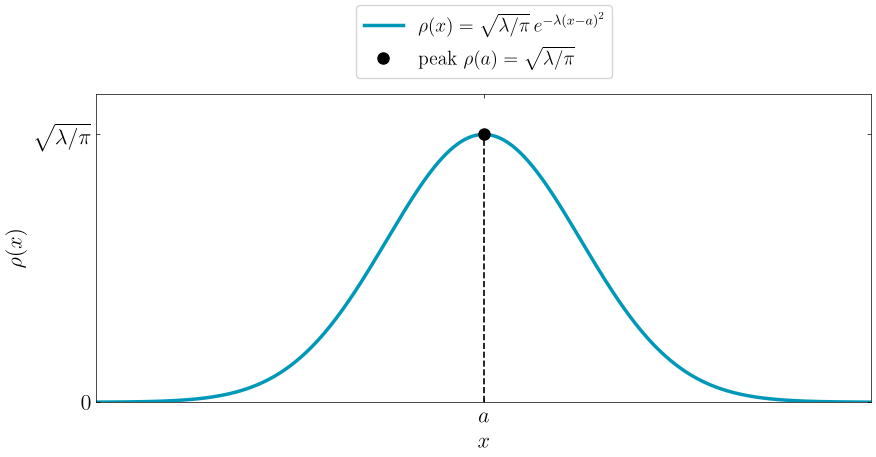

In [3]:
# rho(x) = A exp(-lambda (x - a)^2),  A = sqrt(lambda/pi),  sigma = 1/sqrt(2 lambda)
# Gaussian centered at a, peak A. Take a = 0, lambda = 1
# and label ticks symbolically so the sketch holds for any a, lambda.
a, lam = 0.0, 1.0
A = np.sqrt(lam/np.pi)
sigma = 1/np.sqrt(2*lam)

x = np.linspace(a - 4*sigma, a + 4*sigma, 801)
rho = A*np.exp(-lam*(x - a)**2)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(x, rho, color=C.cyan, linewidth=2.5, label=r'$\rho(x) = \sqrt{\lambda/\pi}\, e^{-\lambda (x - a)^2}$')
ax.vlines(a, 0, A, colors=FG, linestyles='--', linewidths=1.2)
ax.plot(a, A, 'o', color=FG, markersize=8, zorder=3, label=r'peak $\rho(a) = \sqrt{\lambda/\pi}$')

style_ax(ax, xlabel='$x$', ylabel=r'$\rho(x)$', xlim=(a - 4*sigma, a + 4*sigma), ylim=(0, 1.15*A),
         xticks=[a], xticklabels=['$a$'],
         yticks=[0, A], yticklabels=['$0$', r'$\sqrt{\lambda/\pi}$'])
ax.legend(frameon=True, fontsize=14, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=1)

savefig(fig, "chap1ex1.3c.pdf")
plt.show()


Question 1.4

(b)

saved chap1ex1.4b.pdf -> \\wsl.localhost\Ubuntu-22.04\home\cantorian_infinity\physics\introquantummechanics\chap1\chap1ex1.4b.pdf


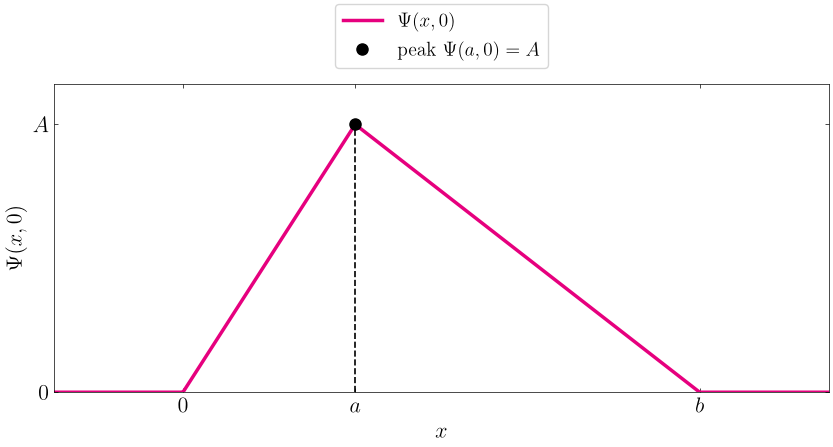

In [4]:
# Psi(x,0) = A x/a on [0,a],  A (b-x)/(b-a) on [a,b],  0 otherwise.  Peak A at x = a.
# Take a = 1, b = 3 and label ticks symbolically so the sketch holds for any 0 < a < b.
a, b, A = 1.0, 3.0, 1.0

x = np.linspace(-0.25*b, 1.25*b, 801)
psi = np.where((x >= 0) & (x <= a), A*x/a,
      np.where((x > a) & (x <= b), A*(b - x)/(b - a), 0.0))

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(x, psi, color=C.magenta, linewidth=2.5, label=r'$\Psi(x, 0)$')
ax.vlines(a, 0, A, colors=FG, linestyles='--', linewidths=1.2)
ax.plot(a, A, 'o', color=FG, markersize=8, zorder=3, label=r'peak $\Psi(a, 0) = A$')

style_ax(ax, xlabel='$x$', ylabel=r'$\Psi(x, 0)$', xlim=(-0.25*b, 1.25*b), ylim=(0, 1.15*A),
         xticks=[0, a, b], xticklabels=['$0$', '$a$', '$b$'],
         yticks=[0, A], yticklabels=['$0$', '$A$'])
ax.legend(frameon=True, fontsize=14, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=1)

savefig(fig, "chap1ex1.4b.pdf")
plt.show()


Question 1.5

(c)

saved chap1ex1.5c.pdf -> \\wsl.localhost\Ubuntu-22.04\home\cantorian_infinity\physics\introquantummechanics\chap1\chap1ex1.5c.pdf


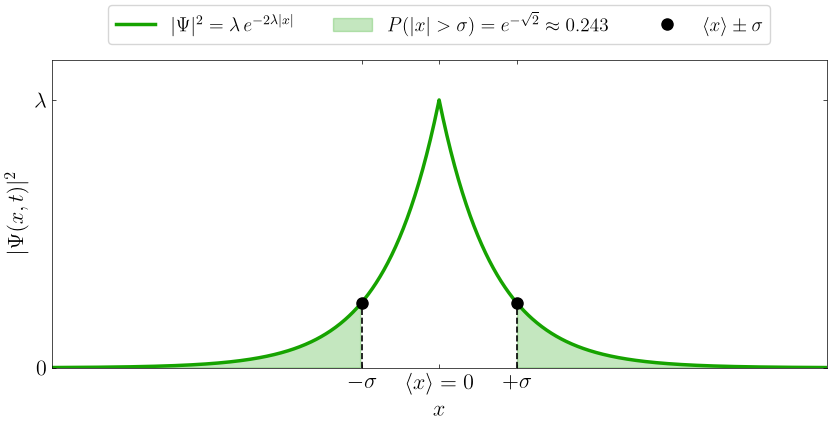

In [5]:
# |Psi|^2 = A^2 exp(-2 lambda |x|),  A = sqrt(lambda)  (normalization),  <x> = 0,  <x^2> = 1/(2 lambda^2),  sigma = 1/(sqrt(2) lambda).
# P(outside <x> +/- sigma) = exp(-2 lambda sigma) = exp(-sqrt(2)) ~ 0.243.
# Take lambda = 1 and label ticks symbolically so the sketch holds for any lambda > 0.
lam = 1.0
A2 = lam
sigma = 1/(np.sqrt(2)*lam)
p_out = np.exp(-np.sqrt(2))

x = np.linspace(-5*sigma, 5*sigma, 801)
rho = A2*np.exp(-2*lam*np.abs(x))

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(x, rho, color=C.green, linewidth=2.5, label=r'$|\Psi|^2 = \lambda\, e^{-2\lambda|x|}$')
ax.fill_between(x, rho, where=np.abs(x) > sigma, color=C.green, alpha=0.25,
                label=rf'$P(|x| > \sigma) = e^{{-\sqrt{{2}}}} \approx {p_out:.3f}$')
ax.vlines([-sigma, sigma], 0, A2*np.exp(-2*lam*sigma), colors=FG, linestyles='--', linewidths=1.2)
ax.plot([-sigma, sigma], [A2*np.exp(-2*lam*sigma)]*2, 'o', color=FG, markersize=8, zorder=3,
        label=r'$\langle x \rangle \pm \sigma$')

style_ax(ax, xlabel='$x$', ylabel=r'$|\Psi(x, t)|^2$', xlim=(-5*sigma, 5*sigma), ylim=(0, 1.15*A2),
         xticks=[-sigma, 0, sigma], xticklabels=[r'$-\sigma$', r'$\langle x \rangle = 0$', r'$+\sigma$'],
         yticks=[0, A2], yticklabels=['$0$', r'$\lambda$'])
ax.legend(frameon=True, fontsize=14, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=3)

savefig(fig, "chap1ex1.5c.pdf")
plt.show()


Question 1.11

(a)

saved chap1ex1.11a.pdf -> \\wsl.localhost\Ubuntu-22.04\home\cantorian_infinity\physics\introquantummechanics\chap1\chap1ex1.11a.pdf


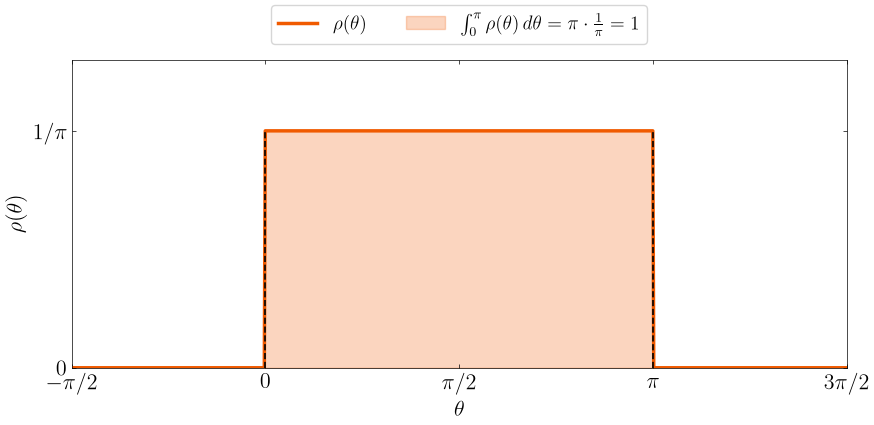

In [6]:
# rho(theta) = 1/pi on [0, pi], 0 otherwise (uniform: needle equally likely at any angle).
# Normalization: integral_0^pi (1/pi) d(theta) = 1.
rho0 = 1/np.pi

theta = np.linspace(-np.pi/2, 3*np.pi/2, 801)
rho = np.where((theta >= 0) & (theta <= np.pi), rho0, 0.0)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(theta, rho, color=C.orange, linewidth=2.5, label=r'$\rho(\theta)$')
ax.fill_between(theta, rho, color=C.orange, alpha=0.25,
                label=r'$\int_0^{\pi} \rho(\theta)\, d\theta = \pi \cdot \frac{1}{\pi} = 1$')
ax.vlines([0, np.pi], 0, rho0, colors=FG, linestyles='--', linewidths=1.2)

style_ax(ax, xlabel=r'$\theta$', ylabel=r'$\rho(\theta)$', xlim=(-np.pi/2, 3*np.pi/2), ylim=(0, 1.3*rho0),
         xticks=[-np.pi/2, 0, np.pi/2, np.pi, 3*np.pi/2],
         xticklabels=[r'$-\pi/2$', '$0$', r'$\pi/2$', r'$\pi$', r'$3\pi/2$'],
         yticks=[0, rho0], yticklabels=['$0$', r'$1/\pi$'])
ax.legend(frameon=True, fontsize=14, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2)

savefig(fig, "chap1ex1.11a.pdf")
plt.show()


saved chap1ex1.11a_sim.pdf -> \\wsl.localhost\Ubuntu-22.04\home\cantorian_infinity\physics\introquantummechanics\chap1\chap1ex1.11a_sim.pdf


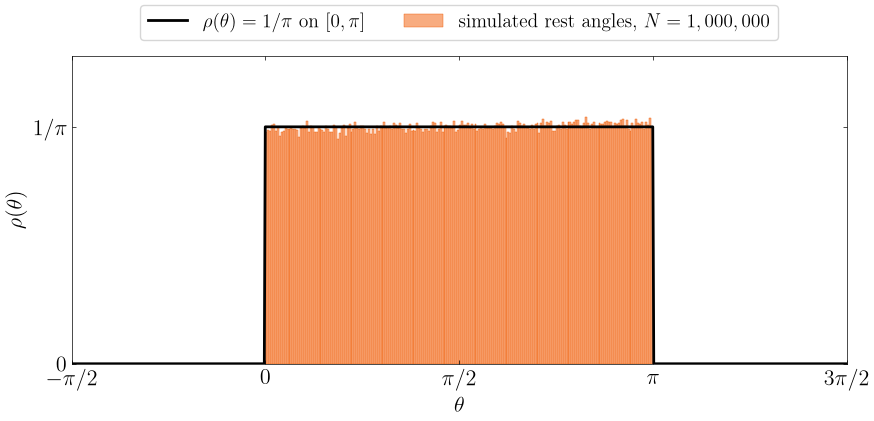

In [7]:
# Monte Carlo of the flicked needle.  Each flick: start at angle theta0 in [0, pi], give angular speed w0,
# friction decelerates it uniformly (alpha), so it travels arc length s = w0^2 / (2 alpha) before stopping.
# Perfect bounces off the pins at 0 and pi fold that travel like a triangle wave, so the rest angle is
# the reflection of theta0 + s back into [0, pi].  Large, random s -> the rest angle forgets theta0 -> uniform.
rng = np.random.default_rng(0)
N, alpha = 1_000_000, 1.0
theta0 = rng.uniform(0, np.pi, N)
w0 = rng.uniform(5, 30, N)                         # any broad flick distribution gives the same answer
s = w0**2 / (2*alpha)
rest = np.pi - np.abs(((theta0 + s) % (2*np.pi)) - np.pi)   # fold onto [0, pi]

edges = np.linspace(-np.pi/2, 3*np.pi/2, 401)
counts, _ = np.histogram(rest, bins=edges, density=True)
assert np.isclose(np.sum(counts*np.diff(edges)), 1.0)       # total probability 1

fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(edges[:-1], counts, width=np.diff(edges), align='edge', color=tint(C.orange), edgecolor=C.orange,
       linewidth=0.3, label=rf'simulated rest angles, $N = {N:,}$')
theta = np.linspace(-np.pi/2, 3*np.pi/2, 801)
ax.plot(theta, np.where((theta >= 0) & (theta <= np.pi), 1/np.pi, 0.0), color=FG, linewidth=2,
        label=r'$\rho(\theta) = 1/\pi$ on $[0, \pi]$')

style_ax(ax, xlabel=r'$\theta$', ylabel=r'$\rho(\theta)$', xlim=(-np.pi/2, 3*np.pi/2), ylim=(0, 1.3/np.pi),
         xticks=[-np.pi/2, 0, np.pi/2, np.pi, 3*np.pi/2],
         xticklabels=[r'$-\pi/2$', '$0$', r'$\pi/2$', r'$\pi$', r'$3\pi/2$'],
         yticks=[0, 1/np.pi], yticklabels=['$0$', r'$1/\pi$'])
ax.legend(frameon=True, fontsize=14, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2)

savefig(fig, "chap1ex1.11a_sim.pdf")
plt.show()


Question 1.12

saved chap1ex1.12.pdf -> \\wsl.localhost\Ubuntu-22.04\home\cantorian_infinity\physics\introquantummechanics\chap1\chap1ex1.12.pdf


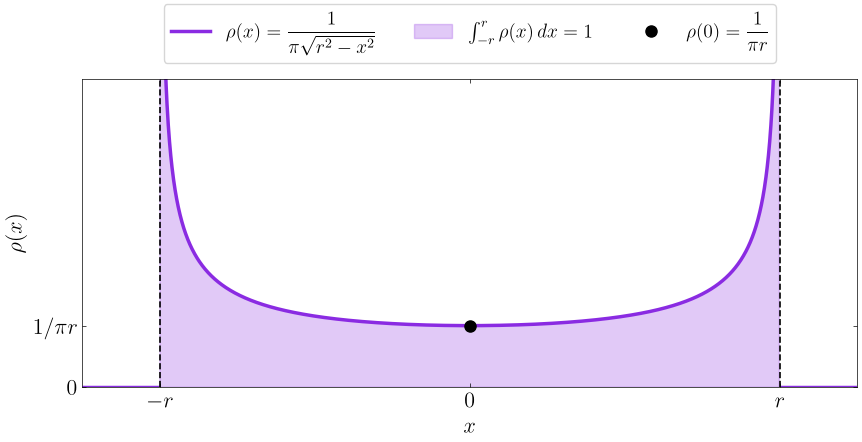

In [8]:
# rho(x) = 1/(pi sqrt(r^2 - x^2)) on (-r, r), 0 otherwise.  Diverges at x = +/- r (integrable).
# Take r = 1 and label ticks symbolically so the sketch holds for any r > 0.
r = 1.0
rho0 = 1/(np.pi*r)                                  # value at x = 0

x = np.linspace(-r, r, 2001)[1:-1]
rho = 1/(np.pi*np.sqrt(r**2 - x**2))

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(x, rho, color=C.violet, linewidth=2.5, label=r'$\rho(x) = \dfrac{1}{\pi\sqrt{r^2 - x^2}}$')
ax.hlines(0, -1.25*r, -r, colors=C.violet, linewidths=2.5)
ax.hlines(0, r, 1.25*r, colors=C.violet, linewidths=2.5)
ax.fill_between(x, rho, color=C.violet, alpha=0.25, label=r'$\int_{-r}^{r} \rho(x)\, dx = 1$')
ax.vlines([-r, r], 0, 5*rho0, colors=FG, linestyles='--', linewidths=1.2)
ax.plot(0, rho0, 'o', color=FG, markersize=8, zorder=3, label=r'$\rho(0) = \dfrac{1}{\pi r}$')

style_ax(ax, xlabel='$x$', ylabel=r'$\rho(x)$', xlim=(-1.25*r, 1.25*r), ylim=(0, 5*rho0),
         xticks=[-r, 0, r], xticklabels=['$-r$', '$0$', '$r$'],
         yticks=[0, rho0], yticklabels=['$0$', r'$1/\pi r$'])
ax.legend(frameon=True, fontsize=14, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=3)

savefig(fig, "chap1ex1.12.pdf")
plt.show()


saved chap1ex1.12_sim.pdf -> \\wsl.localhost\Ubuntu-22.04\home\cantorian_infinity\physics\introquantummechanics\chap1\chap1ex1.12_sim.pdf


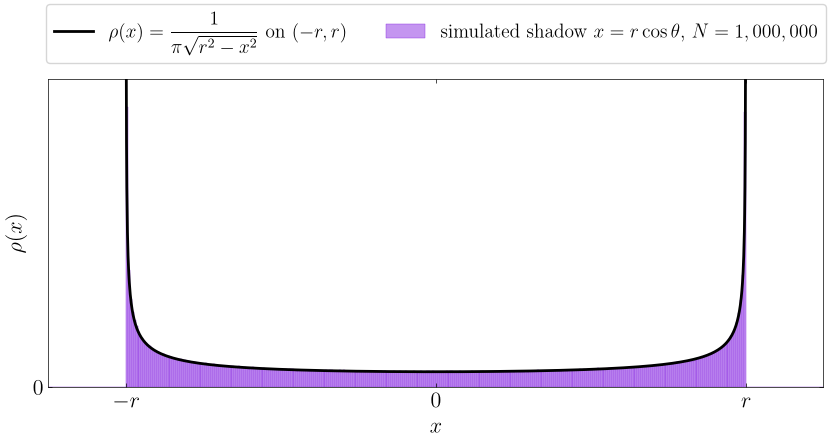

In [9]:
# Same device as 1.11: reuse the simulated rest angles `rest` from the cell above.
# Needle of length r; the point's shadow on the horizontal line is x = r cos(theta).
r = 1.0
xs = r*np.cos(rest)

edges = np.linspace(-1.25*r, 1.25*r, 401)
counts, _ = np.histogram(xs, bins=edges, density=True)
assert np.isclose(np.sum(counts*np.diff(edges)), 1.0)       # total probability 1

fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(edges[:-1], counts, width=np.diff(edges), align='edge', color=tint(C.violet), edgecolor=C.violet,
       linewidth=0.3, label=rf'simulated shadow $x = r\cos\theta$, $N = {N:,}$')
x = np.linspace(-r, r, 2001)[1:-1]
ax.plot(x, 1/(np.pi*np.sqrt(r**2 - x**2)), color=FG, linewidth=2,
        label=r'$\rho(x) = \dfrac{1}{\pi\sqrt{r^2 - x^2}}$ on $(-r, r)$')

style_ax(ax, xlabel='$x$', ylabel=r'$\rho(x)$', xlim=(-1.25*r, 1.25*r), ylim=(0, 1.1*counts.max()),
         xticks=[-r, 0, r], xticklabels=['$-r$', '$0$', '$r$'],
         yticks=[0], yticklabels=['$0$'])
ax.legend(frameon=True, fontsize=14, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2)

savefig(fig, "chap1ex1.12_sim.pdf")
plt.show()


Question 1.13

In [ ]:
# Monte Carlo of Buffon's needle.  Reuse the uniform rest angles `rest` from 1.11 (the hint: angle is
# uniform on [0, pi], as in 1.12).  Second coordinate: distance d from the needle's center to the nearest line,
# uniform on [0, l/2].  The needle's half-length projects to (l/2) sin(theta) across the lines, so it crosses
# iff d < (l/2) sin(theta).  Exact: P = (2/(pi l)) int_0^pi (l/2) sin(theta) d(theta) = 2/pi.
l = 1.0
d = rng.uniform(0, l/2, N)
cross = d < (l/2)*np.sin(rest)

n = np.unique(np.logspace(0, np.log10(N), 2000).astype(int))   # log-spaced sample of drop counts
p_run = np.cumsum(cross)[n - 1]/n                   # running estimate after n drops
p_exact = 2/np.pi
sigma_n = np.sqrt(p_exact*(1 - p_exact)/n)          # std of a mean of n Bernoulli(p) trials
assert abs(p_run[-1] - p_exact) < 5*sigma_n[-1]

fig, ax = plt.subplots(figsize=(10, 4))

ax.fill_between(n, p_exact - sigma_n, p_exact + sigma_n, color=tint(C.blue), edgecolor='none',
                label=r'$2/\pi \pm \sqrt{p(1-p)/n}$')
ax.plot(n, p_run, color=C.blue, linewidth=1.5, label=rf'running estimate, $N = {N:,}$ drops')
ax.axhline(p_exact, color=FG, linewidth=2, label=rf'$P = 2/\pi \approx {p_exact:.4f}$')
ax.set_xscale('log')

style_ax(ax, xlabel='drops $n$', ylabel='fraction crossing a line', xlim=(10, N), ylim=(0.5, 0.78),
         yticks=[0.5, p_exact, 0.75], yticklabels=['$0.50$', r'$2/\pi$', '$0.75$'])
ax.legend(frameon=True, fontsize=14, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=3)

savefig(fig, "chap1ex1.13_sim.pdf")
plt.show()
